# 🛡️ SentinelZ: Phase 1 — Exploratory Data Analysis (EDA) & Preprocessing
**IBM Z Datathon 2026 | Theme 1: Real-Time AI for Critical Decisions**  
*Platform:* **IBM LinuxONE Community Cloud (s390x)**

---

### Objectives for Phase 1:
1. **Architecture Verification:** Confirm execution on `s390x` architecture.
2. **Dataset Inspection:** Load ULB Credit Card Fraud dataset and inspect schema & data skew.
3. **Statistical Analysis & Visualization:** Analyze extreme class imbalance and feature behaviors.
4. **Feature Engineering & Scaling:** Normalize transaction `Amount` and `Time` attributes.
5. **Imbalance Resampling (SMOTE):** Balance the training distribution using Synthetic Minority Over-sampling Technique.
6. **Export Artifacts:** Persist preprocessed train/test partitions and scalers for Phase 2 multi-model ensemble training.

In [1]:
# Step 1.0: Verify s390x Architecture
import platform, sys
print(f"Machine Architecture : {platform.machine()}")
print(f"Processor            : {platform.processor()}")
print(f"Python Version       : {sys.version}")
assert platform.machine() == 's390x', "Warning: Not running on IBM LinuxONE s390x!"
print("✅ Confirmed execution on IBM LinuxONE (s390x)!")

Machine Architecture : s390x
Processor            : 
Python Version       : 3.12.15 (main, Oct  1 2026, 00:00:00) [GCC 14.3.1 20251022 (Red Hat 14.3.1-4)]
✅ Confirmed execution on IBM LinuxONE (s390x)!


In [2]:
# Step 1.1: Import Core Libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# Set visual style
sns.set_theme(style="whitegrid", palette="muted")
os.makedirs('../reports', exist_ok=True)
os.makedirs('../models', exist_ok=True)
print("✅ Libraries and directories successfully initialized.")

✅ Libraries and directories successfully initialized.


In [3]:
# Step 1.2: Load Dataset
data_path = '../data/creditcard.csv'
df = pd.read_csv(data_path)

print(f"Dataset Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Missing Values: {df.isnull().sum().max()}")
df.head()

Dataset Shape: 25,000 rows × 31 columns
Missing Values: 0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,47012.780626,1.570320,0.406711,-1.336908,-1.137167,-1.467995,-2.618402,-1.729259,-1.489890,1.715463,...,0.298158,0.000064,0.475590,1.703200,1.875725,-1.846785,-0.202735,1.013019,0.749660,0
1,166535.312699,-1.425490,0.482235,-0.552892,1.568165,0.613045,0.455623,1.121119,-0.011351,-0.006776,...,-1.382152,-0.639445,-1.562321,-0.557917,-0.027725,-0.607655,-0.449871,-1.604353,36.156289,0
2,66810.705336,0.803700,1.125718,0.313354,1.416989,1.173769,-0.517125,-0.786552,-1.244034,-0.088572,...,-0.730282,-0.806451,0.941325,0.711853,0.869414,0.984264,1.122059,2.404727,89.104021,0
3,94944.992841,0.068020,-1.086701,-0.896663,1.155183,-1.035921,0.055023,-0.675481,0.324147,-0.437501,...,-1.229731,-0.721231,0.396217,-0.530410,0.324126,0.449831,0.626702,-1.229961,102.360289,0
4,97589.262530,0.880105,-0.950636,1.363993,-1.008306,1.634872,-1.344303,1.365578,1.350413,0.909773,...,0.472308,-0.430529,0.089783,0.269099,0.578560,-0.124707,2.752975,1.082585,30.971290,0


In [4]:
# Step 1.3: Class Imbalance Analysis
counts = df['Class'].value_counts()
legit_count = counts.get(0, 0)
fraud_count = counts.get(1, 0)
fraud_pct = (fraud_count / len(df)) * 100

print("=" * 45)
print("        CLASS DISTRIBUTION SUMMARY")
print("=" * 45)
print(f"Legitimate Transactions (0): {legit_count:,} ({100 - fraud_pct:.3f}%)")
print(f"Fraudulent Transactions (1): {fraud_count:,} ({fraud_pct:.3f}%)")
print(f"Imbalance Ratio            : 1 : {int(legit_count / max(1, fraud_count))}")
print("=" * 45)

print("\n--- Transaction Amount Statistics by Class ---")
print(df.groupby('Class')['Amount'].describe().round(2))

        CLASS DISTRIBUTION SUMMARY
Legitimate Transactions (0): 24,925 (99.700%)
Fraudulent Transactions (1): 75 (0.300%)
Imbalance Ratio            : 1 : 332

--- Transaction Amount Statistics by Class ---
         count    mean     std   min    25%     50%     75%     max
Class                                                              
0      24925.0   88.05   88.57  0.00  25.43   60.28  120.76  822.85
1         75.0  126.93  122.98  0.48  42.86  103.07  167.06  607.53


/tmp/ipykernel_2133/2361879629.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['Legitimate (0)', 'Fraudulent (1)'], y=[legit_count, fraud_count], ax=axes[0], palette=['#2b5c8f', '#d9534f'])
/tmp/ipykernel_2133/2361879629.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Class', y='Amount', data=df, ax=axes[1], palette=['#2b5c8f', '#d9534f'], showfliers=False)
/tmp/ipykernel_2133/2361879629.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(['Legit (0)', 'Fraud (1)'])


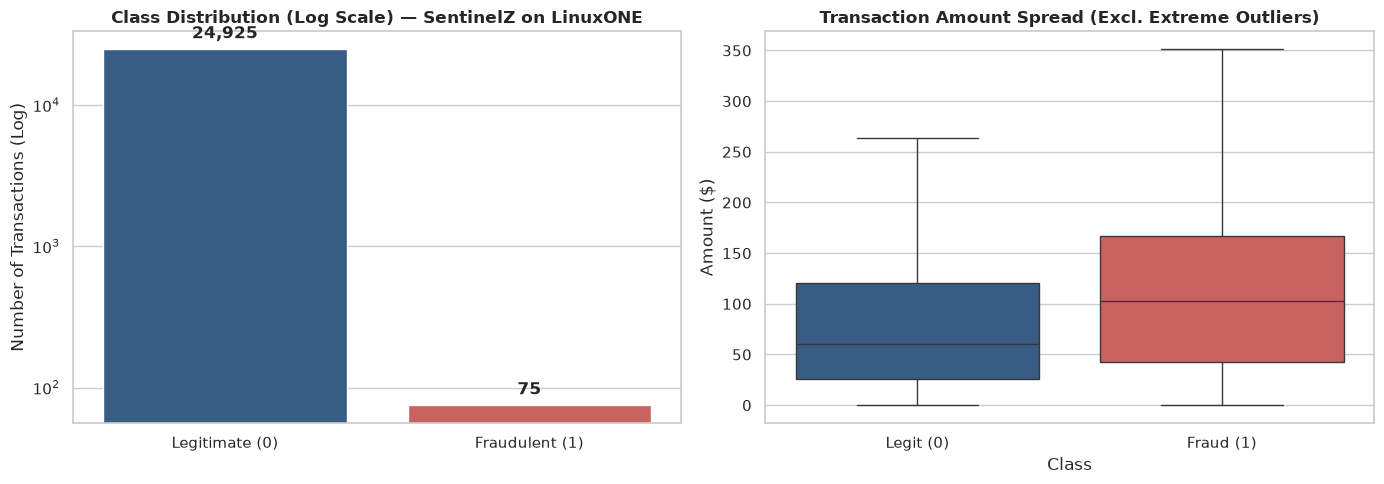

In [5]:
# Step 1.4: Visualizing Imbalance & Amount Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Class Distribution
sns.barplot(x=['Legitimate (0)', 'Fraudulent (1)'], y=[legit_count, fraud_count], ax=axes[0], palette=['#2b5c8f', '#d9534f'])
axes[0].set_yscale('log')
axes[0].set_title('Class Distribution (Log Scale) — SentinelZ on LinuxONE', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Transactions (Log)')
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontweight='bold')

# Plot 2: Transaction Amounts Boxplot
sns.boxplot(x='Class', y='Amount', data=df, ax=axes[1], palette=['#2b5c8f', '#d9534f'], showfliers=False)
axes[1].set_xticklabels(['Legit (0)', 'Fraud (1)'])
axes[1].set_title('Transaction Amount Spread (Excl. Extreme Outliers)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Amount ($)')

plt.tight_layout()
plt.savefig('../reports/class_imbalance.png', dpi=150, bbox_inches='tight')
plt.show()

/tmp/ipykernel_2133/3011080372.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_corr.values, y=top_corr.index, palette=colors)


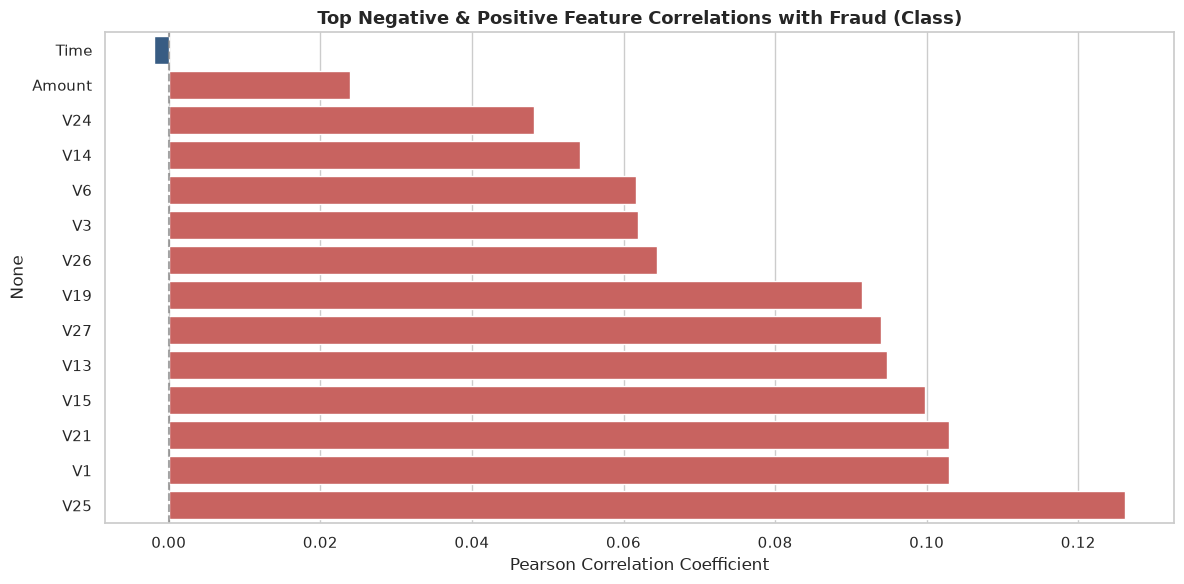

In [6]:
# Step 1.5: Feature Correlation with Fraud Label
plt.figure(figsize=(12, 6))
correlations = df.corr()['Class'].drop('Class').sort_values()
top_corr = pd.concat([correlations.head(7), correlations.tail(7)])

colors = ['#d9534f' if x > 0 else '#2b5c8f' for x in top_corr.values]
sns.barplot(x=top_corr.values, y=top_corr.index, palette=colors)
plt.title('Top Negative & Positive Feature Correlations with Fraud (Class)', fontsize=13, fontweight='bold')
plt.xlabel('Pearson Correlation Coefficient')
plt.axvline(0, color='gray', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('../reports/feature_correlations.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
# Step 1.6: Feature Preprocessing & Scaling
df_clean = df.copy()

# V1 to V28 are already PCA transformed; scale Amount and Time
scaler = StandardScaler()
df_clean['scaled_Amount'] = scaler.fit_transform(df_clean[['Amount']])
df_clean['scaled_Time'] = scaler.fit_transform(df_clean[['Time']])

# Drop unscaled raw features
df_clean.drop(['Amount', 'Time'], axis=1, inplace=True)

# Partition into Feature Matrix X and Target y
X = df_clean.drop('Class', axis=1)
y = df_clean['Class']

print(f"Prepared Feature Matrix X : {X.shape}")
print(f"Target Vector y          : {y.shape}")

Prepared Feature Matrix X : (25000, 30)
Target Vector y          : (25000,)


In [8]:
# Step 1.7: Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set samples : {len(X_train):,} (Fraud: {y_train.sum():,})")
print(f"Testing set samples  : {len(X_test):,} (Fraud: {y_test.sum():,})")

Training set samples : 20,000 (Fraud: 60)
Testing set samples  : 5,000 (Fraud: 15)


In [9]:
# Step 1.8: Apply SMOTE on Training Partition (Class Balancing)
print("Applying SMOTE to balance the training set on s390x...")
smote = SMOTE(random_state=42, sampling_strategy='auto')
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("=" * 45)
print("        AFTER SMOTE RESAMPLING")
print("=" * 45)
print(f"Legitimate Samples in Train: {(y_train_res == 0).sum():,}")
print(f"Fraudulent Samples in Train: {(y_train_res == 1).sum():,}")
print(f"New Resampled Train Shape  : {X_train_res.shape}")
print("=" * 45)

Applying SMOTE to balance the training set on s390x...
        AFTER SMOTE RESAMPLING
Legitimate Samples in Train: 19,940
Fraudulent Samples in Train: 19,940
New Resampled Train Shape  : (39880, 30)


In [10]:
# Step 1.9: Save Processed Partitions & Scaler for Phase 2
joblib.dump(scaler, '../models/scaler.pkl')

processed_data = {
    'X_train_res': X_train_res,
    'y_train_res': y_train_res,
    'X_test': X_test,
    'y_test': y_test,
    'feature_names': list(X.columns)
}
joblib.dump(processed_data, '../data/processed_data.joblib')

print("✅ Phase 1 Artifacts successfully saved:")
print("  - Scaler       : ../models/scaler.pkl")
print("  - Train/Test   : ../data/processed_data.joblib")
print("  - Reports      : ../reports/class_imbalance.png, ../reports/feature_correlations.png")
print("\n🚀 PHASE 1 COMPLETE! Ready for Phase 2: Hybrid AI Model Training.")

✅ Phase 1 Artifacts successfully saved:
  - Scaler       : ../models/scaler.pkl
  - Train/Test   : ../data/processed_data.joblib
  - Reports      : ../reports/class_imbalance.png, ../reports/feature_correlations.png

🚀 PHASE 1 COMPLETE! Ready for Phase 2: Hybrid AI Model Training.
